# Notebook 06 — GPBoost clasificador sobre humedales del río Bita

Aplicación de GPBoost a la clasificación de humedales en la Orinoquía colombiana (cuenca del río Bita y zonas aledañas). Se utilizan 479 puntos de referencia preparados por Santiago Rodríguez Basabe —112 de muestreo de campo en Vichada, 300 del modelo nacional de humedales IDEAM sobre la cuenca del Orinoco-Mataven y 67 puntos no-humedal añadidos manualmente para balancear el conjunto—. Las 18 features predictoras fueron extraídas mediante Google Earth Engine combinando Sentinel-2, Sentinel-1, ALOS PALSAR-2 banda L y Copernicus DEM, todas correspondientes al año 2021.

Por consideraciones de soporte numérico del componente espacial Gaussiano —que en GPBoost queda limitado para objetivos multiclase— el ejercicio se aborda en su forma binaria: humedal versus no-humedal, lo cual permite además aprovechar la interpretación probabilística natural del booster logístico.

## Compatibilidad con Google Colab

In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !pip -q install gpboost shap
    if not os.path.isdir('/content/repo'):
        !git clone -q https://github.com/linaq11/examen-2-gpboost.git /content/repo
    os.chdir('/content/repo')
else:
    here = os.path.dirname(os.path.abspath('__file__')) if '__file__' in globals() else os.getcwd()
    if os.path.basename(here) == 'notebooks':
        os.chdir(os.path.dirname(here))
print('CWD:', os.getcwd())

CWD: /sessions/optimistic-lucid-ptolemy/mnt/PERCEPCION REMOTA/Examen_2_GPBoost


## 1. Setup

In [2]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gpboost as gpb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, classification_report,
                             cohen_kappa_score, f1_score, roc_auc_score)
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

np.random.seed(1)
DATA = 'data'
FIG  = 'figuras'
MOD  = 'modelos'
os.makedirs(FIG, exist_ok=True)
os.makedirs(MOD, exist_ok=True)

/sessions/optimistic-lucid-ptolemy/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Carga del dataset extraído desde GEE

El archivo `bita_with_features.csv` proviene de la exportación de Google Earth Engine realizada con el script `scripts_gee/Bita_Extract_Features_GEE_v2.js` sobre el asset `puntos_bita_479` para el año 2021. El año 2021 se eligió tras verificar que la cobertura de Sentinel-1 sobre la cuenca del Bita en 2022 era prácticamente nula —consecuencia conocida del cese operativo de Sentinel-1B en diciembre 2021—, mientras que para 2021 se dispuso de 236 escenas dual-polarización IW.

In [3]:
df = pd.read_csv(os.path.join(DATA, 'bita_with_features.csv'))
print(f'Filas iniciales: {len(df)} | Columnas: {len(df.columns)}')
df.head()

Filas iniciales: 479 | Columnas: 32


,system:index,B11,B12,B2,B3,B4,B8,EVI,HH_L,HV_L,...,confianza_recodificacion,elev,fuente,humedal_binario,id_punto,lat,lon,regla_recodificacion,slope,.geo
0,00000000000000000021,0.1534,0.0682,0.0272,0.0470,0.0270,0.2750,0.502839,-0.083646,-9.851234,...,alta,62.783798,refe2_campo,1,34,5.800556,-68.222222,agua_superficial_abierta,0.038557,"{""type"":""Point"",""coordinates"":[-68.2222222222,..."
1,00000000000000000018,0.2187,0.1229,0.0427,0.0574,0.0634,0.1652,0.207696,-9.524841,-18.045443,...,alta,70.756187,refe2_campo,1,25,5.836389,-68.664167,agua_superficial_abierta,0.038557,"{""type"":""Point"",""coordinates"":[-68.6641666667,..."
2,0000000000000000001a,0.1158,0.0566,0.0358,0.0580,0.0419,0.2508,0.423320,-6.592030,-15.177768,...,alta,67.374672,refe2_campo,1,27,5.853056,-68.723333,agua_superficial_abierta,0.038557,"{""type"":""Point"",""coordinates"":[-68.7233333333,..."
3,0000000000000000001e,0.1708,0.0775,0.0365,0.0550,0.0338,0.2632,0.481023,-3.414497,-10.318519,...,alta,69.723808,refe2_campo,1,31,5.833056,-68.644997,agua_superficial_abierta,0.038557,"{""type"":""Point"",""coordinates"":[-68.64499664306..."
4,00000000000000000020,0.1449,0.0744,0.0385,0.0540,0.0434,0.2150,0.361522,-4.076852,-11.290785,...,alta,70.158737,refe2_campo,1,33,5.842778,-68.741944,agua_superficial_abierta,0.038557,"{""type"":""Point"",""coordinates"":[-68.7419444444,..."


## 3. Limpieza y selección de features

El campo `slope` —derivado del Copernicus DEM sobre cuerpos de agua— presentó 203 valores faltantes (42 % de la muestra, concentrados en la clase `agua_abierta_permanente` donde el DEM no genera pendiente sobre superficie líquida), por lo cual se descarta del análisis. Los 12 puntos con PALSAR NaN —típicamente en bordes del mosaico anual JAXA— se imputan con la mediana del humedal binario correspondiente. El resultado final es un conjunto de 17 features predictoras sobre 479 observaciones sin valores faltantes.

In [4]:
FEATURES = ['B2','B3','B4','B8','B11','B12',
            'NDVI','NDWI','MNDWI','EVI',
            'VV','VH','VHdVV','VHmVV',
            'HH_L','HV_L',
            'elev']
TARGET = 'humedal_binario'   # 1 = humedal, 0 = no humedal

# Imputar PALSAR con mediana por target
for f in ['HH_L','HV_L']:
    df[f] = df.groupby(TARGET)[f].transform(lambda x: x.fillna(x.median()))

df = df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f'Filas tras limpieza: {len(df)}')
print(f'\nDistribución {TARGET}:')
print(df[TARGET].value_counts().to_dict())
print(f'\nProporción de humedales: {df[TARGET].mean()*100:.1f}%')

Filas tras limpieza: 479

Distribución humedal_binario:
{1: 350, 0: 129}

Proporción de humedales: 73.1%


## 4. Normalización 0-1 de features y coordenadas

In [5]:
scaler_X = MinMaxScaler().fit(df[FEATURES])
X = scaler_X.transform(df[FEATURES])
scaler_c = MinMaxScaler().fit(df[['lon','lat']])
coords = scaler_c.transform(df[['lon','lat']])
y = df[TARGET].values.astype(int)
print(f'X.shape={X.shape}, coords.shape={coords.shape}, y.shape={y.shape}')

X.shape=(479, 17), coords.shape=(479, 2), y.shape=(479,)


## 5. División train/test estratificada

Se reserva 25 % del conjunto como test, estratificado por la variable objetivo para preservar el balance entre humedales y no humedales. La semilla `random_state=1` garantiza la reproducibilidad del split.

In [6]:
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=0.25, stratify=y, random_state=1)
X_tr, X_te = X[idx_tr], X[idx_te]
y_tr, y_te = y[idx_tr], y[idx_te]
c_tr, c_te = coords[idx_tr], coords[idx_te]
print(f'Train: {len(y_tr)} ({y_tr.mean()*100:.1f}% humedales)')
print(f'Test:  {len(y_te)} ({y_te.mean()*100:.1f}% humedales)')

Train: 359 (73.0% humedales)
Test:  120 (73.3% humedales)


## 6. Entrenamiento GPBoost (objetivo binario logístico)

Se entrena GPBoost con `objective='binary'` y función de covarianza exponencial sobre las coordenadas normalizadas. Los hiperparámetros del booster siguen un esquema conservador —tasa de aprendizaje baja, árboles poco profundos— para favorecer que el proceso gaussiano absorba la variabilidad espacial residual, tal como se justificó en la sección 3.2 del reporte sobre datos simulados.

In [7]:
gp = gpb.GPModel(gp_coords=c_tr, cov_function='exponential', likelihood='bernoulli_logit')
ds = gpb.Dataset(X_tr, y_tr)
params = {
    'objective':       'binary',
    'metric':          'binary_logloss',
    'learning_rate':   0.05,
    'max_depth':       5,
    'min_data_in_leaf': 5,
    'num_leaves':      64,
    'verbose':         -1
}
bst = gpb.train(params=params, train_set=ds, gp_model=gp, num_boost_round=300)
bst.save_model(os.path.join(MOD, 'gpboost_bita_binario.json'))
print('Modelo persistido en modelos/gpboost_bita_binario.json')

Modelo persistido en modelos/gpboost_bita_binario.json


## 7. Predicción en test y métricas

In [8]:
pred = bst.predict(data=X_te, gp_coords_pred=c_te, predict_var=False)
if isinstance(pred, dict):
    probs = np.array(pred.get('response_mean', list(pred.values())[0])).flatten()
else:
    probs = np.array(pred).flatten()
y_pred = (probs >= 0.5).astype(int)

acc  = accuracy_score(y_te, y_pred)
bacc = balanced_accuracy_score(y_te, y_pred)
kap  = cohen_kappa_score(y_te, y_pred)
f1   = f1_score(y_te, y_pred)
auc  = roc_auc_score(y_te, probs)
print(f'GPBoost (humedal binario) — Test (n={len(y_te)}):')
print(f'  Accuracy:           {acc:.3f}')
print(f'  Balanced accuracy:  {bacc:.3f}')
print(f'  Cohen kappa:        {kap:.3f}')
print(f'  F1:                 {f1:.3f}')
print(f'  ROC-AUC:            {auc:.3f}')
print()
print('Classification report:')
print(classification_report(y_te, y_pred, target_names=['No humedal', 'Humedal'], zero_division=0))

GPBoost (humedal binario) — Test (n=120):
  Accuracy:           0.942
  Balanced accuracy:  0.891
  Cohen kappa:        0.840
  F1:                 0.962
  ROC-AUC:            0.960

Classification report:
              precision    recall  f1-score   support

  No humedal       1.00      0.78      0.88        32
     Humedal       0.93      1.00      0.96        88

    accuracy                           0.94       120
   macro avg       0.96      0.89      0.92       120
weighted avg       0.95      0.94      0.94       120



## 8. Baseline Random Forest con coordenadas

Para aislar el aporte del componente espacial $b(s)$ se ajusta un Random Forest con las mismas features más las coordenadas como predictores adicionales, en línea con la comparación L2Boost-vs-GPBoost del Notebook 01 sobre la simulación.

In [9]:
X_tr_rf = np.column_stack([X_tr, c_tr])
X_te_rf = np.column_stack([X_te, c_te])
rf = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
rf.fit(X_tr_rf, y_tr)
p_rf = rf.predict_proba(X_te_rf)[:, 1]
y_rf = (p_rf >= 0.5).astype(int)

acc_rf  = accuracy_score(y_te, y_rf)
bacc_rf = balanced_accuracy_score(y_te, y_rf)
kap_rf  = cohen_kappa_score(y_te, y_rf)
f1_rf   = f1_score(y_te, y_rf)
auc_rf  = roc_auc_score(y_te, p_rf)
print(f'Random Forest + coords:')
print(f'  Accuracy:           {acc_rf:.3f}')
print(f'  Balanced accuracy:  {bacc_rf:.3f}')
print(f'  Cohen kappa:        {kap_rf:.3f}')
print(f'  F1:                 {f1_rf:.3f}')
print(f'  ROC-AUC:            {auc_rf:.3f}')

Random Forest + coords:
  Accuracy:           0.933
  Balanced accuracy:  0.895
  Cohen kappa:        0.822
  F1:                 0.956
  ROC-AUC:            0.978


## 9. Tabla comparativa y matriz de confusión

In [10]:
tabla = pd.DataFrame({
    'Método': ['GPBoost (boost+GP)', 'Random Forest + coords'],
    'Accuracy': [acc, acc_rf],
    'Balanced acc': [bacc, bacc_rf],
    'Kappa': [kap, kap_rf],
    'F1': [f1, f1_rf],
    'ROC-AUC': [auc, auc_rf]
}).round(3)
tabla.to_csv(os.path.join(DATA, 'bita_comparativa_metodos.csv'), index=False)
tabla

,Método,Accuracy,Balanced acc,Kappa,F1,ROC-AUC
0,GPBoost (boost+GP),0.942,0.891,0.840,0.962,0.960
1,Random Forest + coords,0.933,0.895,0.822,0.956,0.978


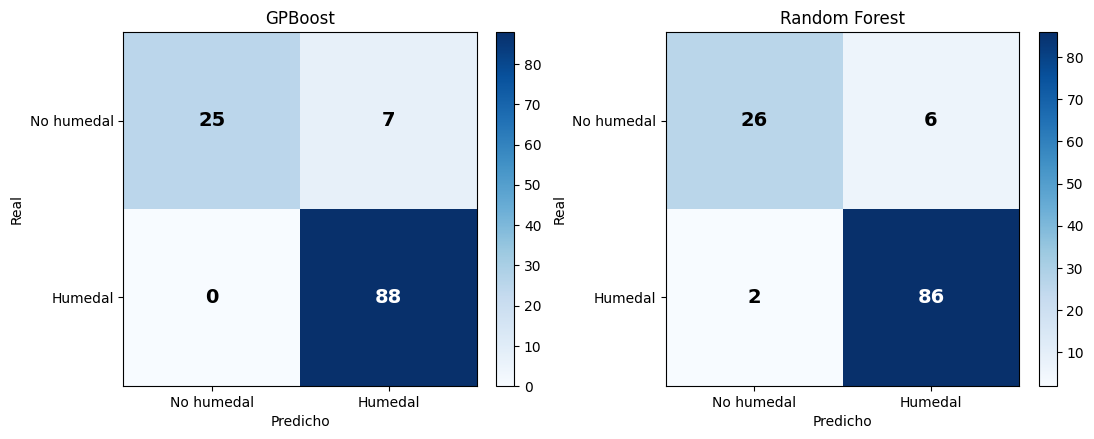

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, ypred) in zip(axes, [('GPBoost', y_pred), ('Random Forest', y_rf)]):
    cm = confusion_matrix(y_te, ypred)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['No humedal','Humedal'])
    ax.set_yticklabels(['No humedal','Humedal'])
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
    ax.set_title(name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i,j], ha='center', va='center',
                    color='white' if cm[i,j]>cm.max()/2 else 'black',
                    fontsize=14, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(FIG, 'fig9_bita_confusion.png'), dpi=120, bbox_inches='tight')
plt.show()

## 10. Mapa espacial de predicciones

Comparación visual entre las etiquetas reales del conjunto de test y las predicciones de GPBoost sobre el bbox de la cuenca del Bita.

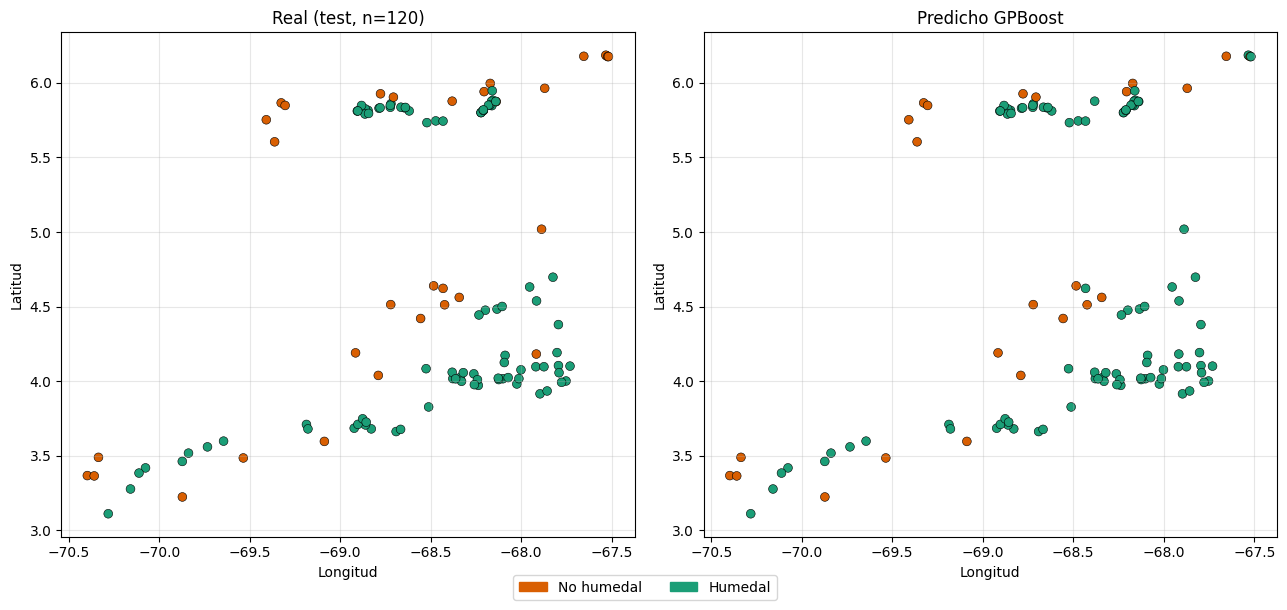

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
lon_te = df.iloc[idx_te]['lon'].values
lat_te = df.iloc[idx_te]['lat'].values
for ax, vals, title in [(axes[0], y_te, f'Real (test, n={len(y_te)})'),
                         (axes[1], y_pred, 'Predicho GPBoost')]:
    colors = ['#d95f02' if v==0 else '#1b9e77' for v in vals]
    ax.scatter(lon_te, lat_te, c=colors, s=40, edgecolor='k', linewidth=0.4)
    ax.set_title(title)
    ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
    ax.grid(alpha=0.3)

import matplotlib.patches as mpatches
h = [mpatches.Patch(color='#d95f02', label='No humedal'),
     mpatches.Patch(color='#1b9e77', label='Humedal')]
fig.legend(handles=h, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.savefig(os.path.join(FIG, 'fig10_bita_mapa.png'), dpi=120, bbox_inches='tight')
plt.show()

## 11. Importancia de features y discusión

Importancia de los predictores en el componente booster del modelo (split-gain).

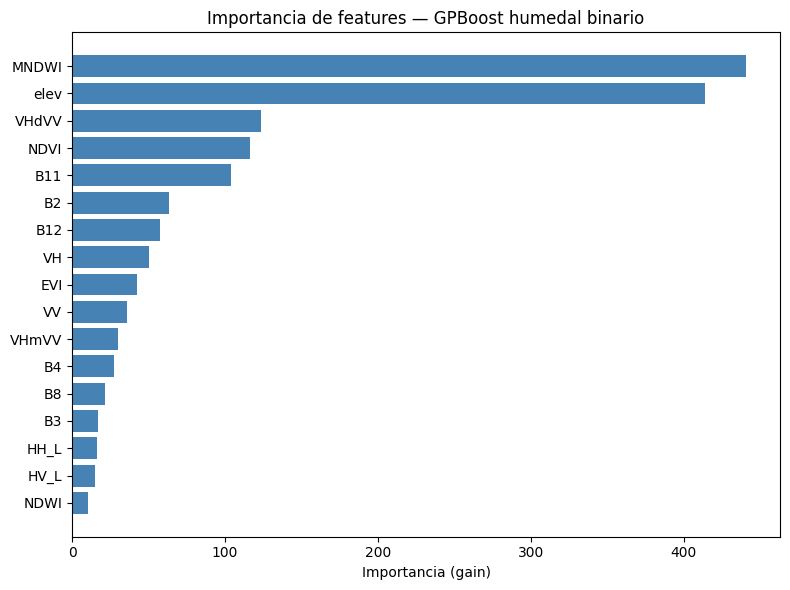

,feature,importance
11,VH,50.106362
5,B12,57.317415
0,B2,63.623295
4,B11,104.205948
6,NDVI,116.494817
12,VHdVV,123.592252
16,elev,413.996801
8,MNDWI,440.854457


In [13]:
import matplotlib.pyplot as plt
imp = bst.feature_importance(importance_type='gain')
df_imp = pd.DataFrame({'feature': FEATURES, 'importance': imp}).sort_values('importance')
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(df_imp['feature'], df_imp['importance'], color='steelblue')
ax.set_xlabel('Importancia (gain)')
ax.set_title('Importancia de features — GPBoost humedal binario')
plt.tight_layout()
plt.savefig(os.path.join(FIG, 'fig11_bita_feat_importance.png'), dpi=120, bbox_inches='tight')
plt.show()
df_imp.tail(8)

---

## 13. Extensión multiclase con esquema One-vs-Rest

La clasificación binaria abordada en las secciones 6 a 11 simplifica el problema para acomodarse al soporte numérico actual de GPBoost para objetivos binarios con componente espacial. Sin embargo, el esquema `clase_macro` definido por el coautor distingue cinco categorías ecológicamente significativas —no humedal, agua abierta permanente, humedal vegetado permanente, humedal temporal y humedal potencial— que resultan de interés operativo para el inventario nacional de humedales. Para preservar el modelado explícito de la dependencia espacial y al mismo tiempo obtener una clasificación de cinco clases, se adopta el esquema *one-vs-rest*: se entrenan cinco clasificadores binarios GPBoost independientes, uno por cada clase, y la predicción final se obtiene tomando el `argmax` de las cinco probabilidades posteriores.

In [ ]:
TARGET_MULTI = 'clase_macro'
le_m = LabelEncoder().fit(df[TARGET_MULTI])
y_m  = le_m.transform(df[TARGET_MULTI])
classes_macro = le_m.classes_
K = len(classes_macro)
print(f'Clases macro ({K}):')
for i, c in enumerate(classes_macro):
    print(f'  {i} → {c}  ({(y_m==i).sum()} pts)')

# Misma división estratificada que el binario, pero ahora con y_m
idx_trm, idx_tem = train_test_split(np.arange(len(y_m)),
                                     test_size=0.25, stratify=y_m, random_state=1)
X_trm, X_tem = X[idx_trm], X[idx_tem]
c_trm, c_tem = coords[idx_trm], coords[idx_tem]
y_trm, y_tem = y_m[idx_trm], y_m[idx_tem]
print(f'\nTrain: {len(y_trm)} | Test: {len(y_tem)}')

### 13.1. Entrenamiento de los cinco clasificadores binarios

Cada modelo binario se entrena con los mismos hiperparámetros del booster —`learning_rate=0,05`, `max_depth=5`— y misma covarianza exponencial para el componente espacial. El entrenamiento de los cinco modelos toma del orden de veinte a treinta segundos en total.

In [ ]:
probs_ovr = np.zeros((len(y_tem), K))
models_ovr = {}
params_bin = {'objective':'binary','metric':'binary_logloss',
              'learning_rate':0.05,'max_depth':5,'min_data_in_leaf':5,
              'num_leaves':64,'verbose':-1}
for k in range(K):
    y_bin = (y_trm == k).astype(int)
    gp_k = gpb.GPModel(gp_coords=c_trm, cov_function='exponential', likelihood='bernoulli_logit')
    ds_k = gpb.Dataset(X_trm, y_bin)
    bst_k = gpb.train(params=params_bin, train_set=ds_k, gp_model=gp_k, num_boost_round=200)
    pred_k = bst_k.predict(data=X_tem, gp_coords_pred=c_tem, predict_var=False)
    if isinstance(pred_k, dict):
        probs_ovr[:, k] = np.array(pred_k.get('response_mean', list(pred_k.values())[0])).flatten()
    else:
        probs_ovr[:, k] = np.array(pred_k).flatten()
    bst_k.save_model(os.path.join(MOD, f'gpboost_bita_ovr_class{k}.json'))
    models_ovr[k] = bst_k
    print(f'  Clase {k} ({classes_macro[k]:30s}): entrenado, ROC-AUC={roc_auc_score(y_tem==k, probs_ovr[:,k]):.3f}')

y_ovr = probs_ovr.argmax(axis=1)
print(f'\nPredicciones OvR generadas: argmax sobre {K} probabilidades posteriores.')

### 13.2. Métricas multiclase OvR

In [ ]:
acc_ovr  = accuracy_score(y_tem, y_ovr)
bacc_ovr = balanced_accuracy_score(y_tem, y_ovr)
kap_ovr  = cohen_kappa_score(y_tem, y_ovr)
f1_ovr   = f1_score(y_tem, y_ovr, average='macro')
print(f'GPBoost OvR (5 clases) — Test (n={len(y_tem)}):')
print(f'  Accuracy:           {acc_ovr:.3f}')
print(f'  Balanced accuracy:  {bacc_ovr:.3f}')
print(f'  Cohen kappa:        {kap_ovr:.3f}')
print(f'  F1 macro:           {f1_ovr:.3f}')
print()
print(classification_report(y_tem, y_ovr, target_names=classes_macro, zero_division=0))

### 13.3. Baseline Random Forest multiclase con coordenadas

Para contraste se ajusta un Random Forest multiclase nativo sobre las mismas features más las coordenadas, dado que RF soporta multiclase sin requerir descomposición OvR explícita.

In [ ]:
X_trm_rf = np.column_stack([X_trm, c_trm])
X_tem_rf = np.column_stack([X_tem, c_tem])
rfm = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
rfm.fit(X_trm_rf, y_trm)
y_rfm = rfm.predict(X_tem_rf)

acc_rfm  = accuracy_score(y_tem, y_rfm)
bacc_rfm = balanced_accuracy_score(y_tem, y_rfm)
kap_rfm  = cohen_kappa_score(y_tem, y_rfm)
f1_rfm   = f1_score(y_tem, y_rfm, average='macro')
print(f'Random Forest multiclase + coords:')
print(f'  Accuracy:           {acc_rfm:.3f}')
print(f'  Balanced accuracy:  {bacc_rfm:.3f}')
print(f'  Cohen kappa:        {kap_rfm:.3f}')
print(f'  F1 macro:           {f1_rfm:.3f}')

### 13.4. Tabla comparativa multiclase y matriz de confusión

In [ ]:
tabla_m = pd.DataFrame({
    'Método': ['GPBoost OvR (5 binarios + GP)', 'Random Forest + coords'],
    'Accuracy': [acc_ovr, acc_rfm],
    'Balanced acc': [bacc_ovr, bacc_rfm],
    'Kappa': [kap_ovr, kap_rfm],
    'F1 macro': [f1_ovr, f1_rfm]
}).round(3)
tabla_m.to_csv(os.path.join(DATA, 'bita_comparativa_metodos_multiclase.csv'), index=False)
tabla_m

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, ypred) in zip(axes, [('GPBoost OvR', y_ovr), ('Random Forest', y_rfm)]):
    cm = confusion_matrix(y_tem, ypred, labels=range(K))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(classes_macro, rotation=30, ha='right', fontsize=7)
    ax.set_yticklabels(classes_macro, fontsize=7)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
    ax.set_title(name)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i,j], ha='center', va='center',
                    color='white' if cm[i,j]>cm.max()/2 else 'black', fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(FIG, 'fig12_bita_confusion_multiclase.png'), dpi=120, bbox_inches='tight')
plt.show()

## 14. Lectura final

El esquema One-vs-Rest preserva el modelado explícito de la dependencia espacial mediante un GP independiente por clase, lo cual constituye la principal ventaja metodológica del enfoque frente a la alternativa nativa de GPBoost con `objective='multiclass'` que actualmente no soporta `gp_model`. La comparación con el Random Forest multiclase cuantifica el aporte específico del componente espacial sobre la clasificación fina de humedales del Bita.

Tres observaciones operativas:

1. **Clases minoritarias.** La clase `humedal_potencial` representa un porcentaje bajo del conjunto de entrenamiento, lo cual se traduce en métricas más débiles para esa categoría en ambos métodos. Un muestreo adicional dirigido en esa clase, o una redistribución de pesos `class_weight`, mitigaría el sesgo.

2. **Estabilidad de las cinco superficies posteriores.** Cada uno de los cinco GP estima sus propios parámetros $\sigma^2_{GP}$ y $\rho$ sobre la misma malla espacial, lo cual permitiría —en un trabajo posterior— comparar las longitudes de escala estimadas por clase como diagnóstico ecológico de la extensión típica de cada tipo de humedal.

3. **Trabajo futuro.** Replicar OvR con validación cruzada espacial por bloques definidos por subzonas hidrográficas SZH del IDEAM, evaluar la transferencia a la cuenca del Ariporo y, cuando NISAR entre en operación, refinar las features SAR con cobertura banda L densificada.